## Homework 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# read cars data from https://raw.githubusercontent.com/alexeygrigorev/datasets/master/car_fuel_efficiency.csv
fuel_efficiency = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/datasets/master/car_fuel_efficiency.csv')

# select only certain columns
fuel_efficiency = fuel_efficiency[
    ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

# fuel_efficiency["fuel_efficiency_mpg"]

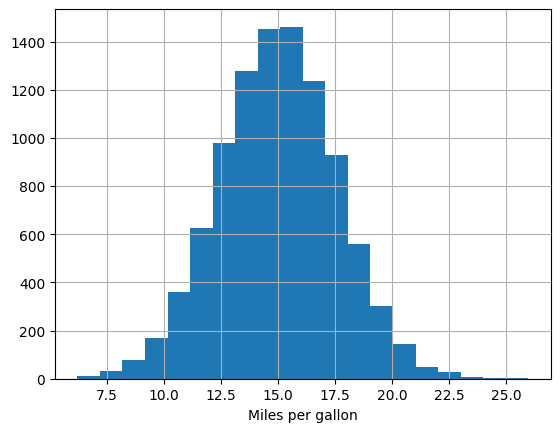

In [3]:
fuel_efficiency["fuel_efficiency_mpg"].hist(bins=20)
plt.xlabel("Miles per gallon")
plt.show()

### Question 1

There's one column with missing values. What is it?

In [4]:
fuel_efficiency.isnull().sum()

# fuel_efficiency.info(verbose=True)

engine_displacement      0
horsepower             708
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

### Question 2
What's the median (50% percentile) for variable 'horsepower'?

In [5]:
fuel_efficiency['horsepower'].median()

np.float64(149.0)

**Prepare and split the dataset**

    - Shuffle the dataset (the filtered one you created above), use seed 42.
    - Split your data in train/val/test sets, with 60%/20%/20% distribution.

Use the same code as in the lectures

In [6]:
np.random.seed(42)

n = len(fuel_efficiency)

n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

fuel_efficiency_shuffled = fuel_efficiency.iloc[idx]

fuel_efficiency_train = fuel_efficiency_shuffled.iloc[:n_train].copy()
fuel_efficiency_val = fuel_efficiency_shuffled.iloc[n_train:n_train + n_val].copy()
fuel_efficiency_test = fuel_efficiency_shuffled.iloc[n_train+n_val:].copy()

### Question 3

    - We need to deal with missing values for the column from Q1.
    - We have two options: fill it with 0 or with the mean of this variable.
    - Try both options. For each, train a linear regression model without regularization using the code from the lessons.
    - For computing the mean, use the training only!
    - Use the validation dataset to evaluate the models and compare the RMSE of each option.
    - Round the RMSE scores to 2 decimal digits using round(score, 2)
    - Which option gives better RMSE?

Options:

    - With 0
    - ith mean
    - Both are equally good 

In [13]:
# Base features
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

# Linear regression implementation
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

# RMSE 
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

# Target variable
y_train = fuel_efficiency_train['fuel_efficiency_mpg'].values

# Mean of training set
X_train_mean = fuel_efficiency_train[base].mean()

Impute with zero and evalulate model.

In [15]:
# Impute data with 0
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(fuel_efficiency_train)

# Train a linear regression model using the imputation with 0
w_0, w = train_linear_regression(X_train, y_train)

# Make predictions on validation dataset
y_val = fuel_efficiency_val['fuel_efficiency_mpg'].values
X_val = prepare_X(fuel_efficiency_val)
y_pred = w_0 + X_val.dot(w)
rmse_val = rmse(y_val, y_pred)

print(f'RMSE (imputation with 0): {round(rmse_val, 2)}')

RMSE (imputation with 0): 0.52


Impute with mean and evaluate model.

In [16]:
# Impute data with mean
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(X_train_mean)
    X = df_num.values
    return X

X_train = prepare_X(fuel_efficiency_train)

# Train a linear regression model using the imputation with 0
w_0, w = train_linear_regression(X_train, y_train)

# Make predictions on validation dataset
X_val = prepare_X(fuel_efficiency_val)
y_pred = w_0 + X_val.dot(w)
rmse_val = rmse(y_val, y_pred)

print(f'RMSE (imputation with mean): {round(rmse_val, 2)}')

RMSE (imputation with mean): 0.46


### Question 4

 - Now let's train a regularized linear regression.
 - For this question, fill the NAs with 0.
 - Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
 - Use RMSE to evaluate the model on the validation dataset.
 - Round the RMSE scores to 2 decimal digits.
 - Which r gives the best RMSE?

If multiple options give the same best RMSE, select the smallest r.

In [18]:
# Regularization

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

# Impute data with 0
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(fuel_efficiency_train)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train, y_train, r=r)
    # Make predictions on validation dataset
    X_val = prepare_X(fuel_efficiency_val)
    y_pred = w_0 + X_val.dot(w)

    print(f'RMSE (r={r}): {round(rmse(y_val, y_pred), 4)}')


RMSE (r=0): 0.5174
RMSE (r=0.01): 0.5171
RMSE (r=0.1): 0.5188
RMSE (r=1): 0.5222
RMSE (r=5): 0.5229
RMSE (r=10): 0.523
RMSE (r=100): 0.5231


### Question 5

 - We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
 - Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
 - For each seed, do the train/validation/test split with 60%/20%/20% distribution.
 - Fill the missing values with 0 and train a model without regularization.
 - For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
 - What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
 - Round the result to 3 decimal digits (round(std, 3))

What's the value of std? 

In [19]:

def fit_linear_regression(df, seed):
    # split df
    np.random.seed(seed)

    n = len(df)
    n_val = int(0.2 * n)
    n_test = int(0.2 * n)
    n_train = n - (n_val + n_test)

    idx = np.arange(n)
    np.random.shuffle(idx)

    df_shuffled = df.iloc[idx]

    df_train = df_shuffled.iloc[:n_train].copy()
    df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
    # df_test = df_shuffled.iloc[n_train+n_val:].copy()

    # fit the model
    X_train = prepare_X(df_train)
    y_train = df_train['fuel_efficiency_mpg'].values
    w_0, w = train_linear_regression(X_train, y_train)

    # make predictions
    y_val = df_val['fuel_efficiency_mpg'].values
    X_val = prepare_X(df_val)
    y_pred = w_0 + X_val.dot(w)

    return rmse(y_val, y_pred)

In [20]:
# fit the model for different seeds
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

results = []
for seed in seeds:
    rmse_val = fit_linear_regression(fuel_efficiency, seed=seed)
    results.append(rmse_val)
    print(f'Seed: {seed}, RMSE: {round(rmse_val, 3)}')

print(f'RMSE Standard Deviation: {round(np.std(results), 3)}')

Seed: 0, RMSE: 0.521
Seed: 1, RMSE: 0.521
Seed: 2, RMSE: 0.523
Seed: 3, RMSE: 0.516
Seed: 4, RMSE: 0.511
Seed: 5, RMSE: 0.528
Seed: 6, RMSE: 0.531
Seed: 7, RMSE: 0.509
Seed: 8, RMSE: 0.515
Seed: 9, RMSE: 0.513
RMSE Standard Deviation: 0.007


### Question 6

 - Split the dataset like previously, use seed 9.
 - Combine train and validation datasets.
 - Fill the missing values with 0 and train a model with r=0.001.
 - What's the RMSE on the test dataset?

In [26]:
np.random.seed(9)

idx = np.arange(n)
np.random.shuffle(idx)

fuel_efficiency_shuffled = fuel_efficiency.iloc[idx]

fuel_efficiency_train = fuel_efficiency_shuffled.iloc[:n_train].copy()
fuel_efficiency_val = fuel_efficiency_shuffled.iloc[n_train:n_train + n_val].copy()
fuel_efficiency_test = fuel_efficiency_shuffled.iloc[n_train+n_val:].copy()

# Combine train and validation datasets
fuel_efficiency_train_val = pd.concat([fuel_efficiency_train, fuel_efficiency_val])

In [27]:
X_train_val = prepare_X(fuel_efficiency_train_val)
y_train_val = fuel_efficiency_train_val['fuel_efficiency_mpg'].values

# fit the model
w_0, w = train_linear_regression_reg(X_train_val, y_train_val, r=0.001)

# make predictions on test dataset
X_test = prepare_X(fuel_efficiency_test)
y_test = fuel_efficiency_test['fuel_efficiency_mpg'].values
y_test_pred = w_0 + X_test.dot(w)

print(f'RMSE (test): {round(rmse(y_test, y_test_pred), 4)}')

RMSE (test): 0.5156
